# AIDA 1141 Final Project – 05 Interpretation and the Cleaning-Repairs Check

**Data version 2** (`shared/synthetic-data/`), using notebook 02's saved model and validation predictions and notebook 04's frozen review policy. Nothing is refitted and no threshold or policy changes.

**Question:** What drives the suggestions, in terms the coordinator can use? Why is the simpler rule supported, and when should a person question it? Do the values that cleaning repaired from other records affect any of this?

Notebook 04 froze policy (a): flag an early-warning assessment when the task's start date is 8 or fewer business days away. This notebook explains that choice for the model card and decision brief:

1. **Cleaning repairs (section A).** Cleaning filled some blank employee types and departments from the same employee's other records, and some of those records were created after the assessment. The notebook checks whether the repairs change who the rule flags, then compares the group results and the model's scores with the repaired values, with only the values available at the time, and with no repairs. The procedure is saved so notebooks 06–07 apply it unchanged to the test set and the time-based check.
2. **What the rule captures and misses (section B),** by days until start.
3. **What the comparison model relies on (section C):** its coefficients and permutation importance.
4. **When the coordinator should question the rule (section D):** a description of the at-risk assessments the rule did not flag, and of the flags on assessments that were not at risk.

Everything uses **validation** data, which has already been used for development in notebooks 02–04. The test set and the time-based check stay unopened, and the simulation's evaluation-only values are not used. All records are synthetic: the rates describe the generator's assumptions, not real employees or real HR performance, and the model's associations are not causes.

In [1]:
import hashlib
import importlib.util
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")

read = lambda path: pd.read_csv(path, dtype=str, keep_default_na=False)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
settings = json.loads((OUTPUT_DIR / "model_settings.json").read_text())          # notebook 02
policy = json.loads((OUTPUT_DIR / "review_policy.json").read_text())             # notebook 04 (frozen)
predictions = pd.read_csv(OUTPUT_DIR / "validation_predictions.csv")             # notebook 02
raw_requests = read(SD / "requests/data/requests.csv")                           # export before cleaning
requests = read(SD / "cleaning/output/requests_cleaned.csv")                     # cleaned (version 1.1)
assessments = read(SD / "requests/data/assessments.csv")
events = read(SD / "requests/data/status_events.csv")
employee_split = read(OUTPUT_DIR / "employee_split.csv")
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())

# Every input must be the one the frozen policy was chosen with
FILES = {"requests_cleaned.csv": SD / "cleaning/output/requests_cleaned.csv",
         "assessments.csv": SD / "requests/data/assessments.csv",
         "employee_split.csv": OUTPUT_DIR / "employee_split.csv", "feature_list.csv": OUTPUT_DIR / "feature_list.csv",
         "model_settings.json": OUTPUT_DIR / "model_settings.json", "model.joblib": OUTPUT_DIR / "model.joblib",
         "validation_predictions.csv": OUTPUT_DIR / "validation_predictions.csv"}
assert {n: sha(p) for n, p in FILES.items()} == policy["fingerprints_sha256"], \
    "An input differs from the fingerprints saved with the frozen policy (notebook 04)"
assert policy["chosen_policy"] == "a" and not policy["model_used"], "The frozen policy is not the days rule"
assert sha(SD / "requests/data/requests.csv") == cleaning_info["source_requests_sha256"] \
    and sha(SD / "requests/data/status_events.csv") == cleaning_info["source_events_sha256"], \
    "The raw export or event log differs from the ones the cleaned file was made from"
model = joblib.load(OUTPUT_DIR / "model.joblib")

# Business-day calendar from the data version 2 generator
spec = importlib.util.spec_from_file_location("generator", SD / "requests/generate_requests.py")
generator = importlib.util.module_from_spec(spec)
spec.loader.exec_module(generator)

# Validation early-warning assessments only (notebook 01's rules); test employees are never loaded into v
split_of = employee_split.set_index("employee_id")["split"]
eligible = assessments[(assessments["employee_id"].map(split_of) == "validation") & (assessments["at_risk"] != "")
                       & (assessments["past_deadline_at_assessment"] == "False")]
assert set(predictions["assessment_id"]) == set(eligible["assessment_id"]) and predictions["assessment_id"].is_unique, \
    "The saved predictions are not exactly the eligible validation assessments"

FEATURES = settings["features"]
v = predictions.merge(assessments[["assessment_id", "assessed_at", "current_status", "business_days_in_current_status",
                                   "team_open_workload"]], on="assessment_id", how="left", validate="one_to_one")
v = v.merge(requests[["request_id", "hiring_department", "intake_channel", "info_issue_at_intake"]],
            on="request_id", how="left", validate="many_to_one")
v["intake_channel"] = v["intake_channel"].replace("", "unknown")              # as in notebook 02
for c in ["business_days_in_current_status", "team_open_workload"]:
    v[c] = v[c].astype(int)
v["assessed_at"] = pd.to_datetime(v["assessed_at"], format="%Y-%m-%dT%H:%M")
v["y"] = v["at_risk"].astype(int)
assert v[FEATURES].notna().all().all() and set(v["employee_id"].map(split_of)) == {"validation"}

DAYS_THRESHOLD = policy["threshold"]
MODEL_THRESHOLD = settings["model_threshold"]
assert np.allclose(model.predict_proba(v[FEATURES])[:, 1], v["risk_probability"], rtol=0, atol=1e-12), \
    "The saved model does not reproduce notebook 02's validation scores"
print(f"Data version {DATA_VERSION}: {len(v):,} validation early-warning assessments, {v['y'].sum()} at risk, "
      f"{v.loc[v['y'] == 1, 'request_id'].nunique()} at-risk tasks, {v['employee_id'].nunique()} employees")
print(f"Frozen policy (a): flag when business days until start <= {DAYS_THRESHOLD}. "
      f"Comparison model threshold (full precision in model_settings.json): {MODEL_THRESHOLD:.4f}")

Data version 2: 1,033 validation early-warning assessments, 194 at risk, 154 at-risk tasks, 209 employees
Frozen policy (a): flag when business days until start <= 8. Comparison model threshold (full precision in model_settings.json): 0.1338


## A. Cleaning repairs: do they change the results?

**What cleaning repaired.** Cleaning version 1.1 filled a blank **employee type** or **hiring department** when the employee's other records all agreed on one value. It also repaired invalid submission times from the request's `submitted` event, but submission time is not a model input or a rule input. The fills were made retrospectively from the full extract, so a filled value can come from a record created **after** the assessment it is used in. Notebook 01 stated this as an assumption; this section tests it.

**Three versions of the two repaired fields,** applied to the same validation assessments; every other input stays the same:

- **Repaired:** the cleaned values used in notebooks 01–04.
- **As of the assessment time:** a filled value is kept only if it could have been known when the assessment was made. Otherwise it becomes unknown.
- **No repairs:** every filled value becomes unknown.

**Donor-availability rule** (for the *as of the assessment time* version). A filled value is available at an assessment only if, at or before the assessment time, at least one of the employee's **other** requests already had a value for that field in the raw export (a value cleaning only standardised, not one it filled):

- **Employee type** is recorded at submission, so a donor's value counts from that donor request's `submitted` event in the status-event log. The event log is used rather than the `submitted_at` field, because cleaning repaired some of those.
- **Hiring department** is confirmed at the information check, so a donor's value counts only from that donor request's information-complete time. A donor still waiting for its information check does not count, which matches cleaning version 1.1.
- If the available donors **disagree**, the value stays unknown. If no donor is available yet, the value is unknown.

The rule is saved to `outputs/repair_check_definition.json` before any comparison is shown, and is protected like the split: notebooks 06–07 must apply it unchanged. Repair counts are reported for requests and for assessments, with the overlap between the two fields.

In [2]:
REPAIRED_FIELDS = ["employee_type", "hiring_department"]
raw = raw_requests.drop_duplicates()                      # cleaning removed exact duplicates first
assert raw["request_id"].is_unique and set(raw["request_id"]) == set(requests["request_id"])
both = requests.merge(raw, on="request_id", suffixes=("", "_raw"), validate="one_to_one")

# A value was filled when the raw export had it blank and the cleaned file does not
filled = pd.DataFrame({f: (both[f + "_raw"].str.strip() == "") & (both[f] != "") for f in REPAIRED_FIELDS})
filled.index = both["request_id"]
for f in REPAIRED_FIELDS:
    logged = next(s["rows"] for s in cleaning_info["steps"] if s["step"] == "employee_level_value_filled" and s["field"] == f)
    assert int(filled[f].sum()) == logged, f"Filled {f} values don't match the cleaning log"

# When each request's own (raw, non-blank) value became available as evidence
submitted_event = pd.to_datetime(events.loc[events["event_type"] == "submitted"].set_index("request_id")["event_at"],
                                 format="%Y-%m-%dT%H:%M")
assert submitted_event.index.is_unique
info_complete = pd.to_datetime(both.set_index("request_id")["info_complete_at"].replace("", None), format="%Y-%m-%dT%H:%M")
assert (both["info_complete_at"] == both["info_complete_at_raw"]).all(), "Cleaning changed an information-complete time"
AVAILABLE_FROM = {"employee_type": submitted_event, "hiring_department": info_complete}
donors = {f: pd.DataFrame({"employee_id": both["employee_id"].to_numpy(), "request_id": both["request_id"].to_numpy(),
                           "value": both[f].to_numpy(),
                           "available_at": both["request_id"].map(AVAILABLE_FROM[f]).to_numpy()})
             .loc[~filled[f].to_numpy() & (both[f].to_numpy() != "")]
          for f in REPAIRED_FIELDS}


def repair_versions(rows):
    # The two repaired fields under each version, for assessment rows with request_id, employee_id and assessed_at
    out = {}
    cleaned = requests.set_index("request_id").loc[rows["request_id"], REPAIRED_FIELDS].set_axis(rows.index)
    for f in REPAIRED_FIELDS:
        was_filled = rows["request_id"].map(filled[f]).astype(bool)
        status = pd.Series("not repaired", index=rows.index)
        as_of = cleaned[f].copy()
        for i in rows.index[was_filled]:
            d = donors[f]
            d = d[(d["employee_id"] == rows.at[i, "employee_id"]) & (d["request_id"] != rows.at[i, "request_id"])
                  & (d["available_at"] <= rows.at[i, "assessed_at"])]
            values = set(d["value"])
            status[i] = ("available" if len(values) == 1 else "conflicting donors" if len(values) > 1
                         else "not yet available")
            if len(values) != 1:
                as_of[i] = "unknown"
            else:
                assert values == {cleaned.at[i, f]}, "An available donor disagrees with the cleaned value"
        out[f] = pd.DataFrame({"repaired": cleaned[f], "as_of_assessment": as_of,
                               "no_repairs": cleaned[f].where(~was_filled, "unknown"), "repair_status": status})
    return out


versions = repair_versions(v)
VERSIONS = ["repaired", "as_of_assessment", "no_repairs"]

# Repair counts: all requests, validation requests in this analysis, and validation assessments, with the overlap between fields
val_requests = filled.loc[filled.index.isin(v["request_id"])]
v_filled = pd.DataFrame({f: v["request_id"].map(filled[f]).astype(bool) for f in REPAIRED_FIELDS})
v_status = pd.DataFrame({f: versions[f]["repair_status"] for f in REPAIRED_FIELDS})
count_rows = []
for level, frame, status in [("requests (all splits)", filled, None),
                             ("validation requests with an early-warning assessment", val_requests, None),
                             ("validation early-warning assessments", v_filled, v_status)]:
    row = {"level": level, "total": len(frame), "employee_type_filled": int(frame["employee_type"].sum()),
           "hiring_department_filled": int(frame["hiring_department"].sum()),
           "both_fields_filled": int(frame.all(axis=1).sum()), "either_field_filled": int(frame.any(axis=1).sum())}
    if status is not None:                                 # timing applies to assessments only
        for f in REPAIRED_FIELDS:
            row[f"{f}_not_yet_available"] = int((status[f] == "not yet available").sum())
            row[f"{f}_conflicting_donors"] = int((status[f] == "conflicting donors").sum())
        row["either_unavailable_as_of_assessment"] = int(status.isin(["not yet available", "conflicting donors"])
                                                         .any(axis=1).sum())
    count_rows.append(row)
repair_counts = pd.DataFrame(count_rows)
for c in repair_counts.columns.drop("level"):
    repair_counts[c] = repair_counts[c].astype("Int64")     # timing columns are blank for the request rows
repair_counts.insert(0, "data_version", DATA_VERSION)
repair_counts.to_csv(OUTPUT_DIR / "repair_counts.csv", index=False)

status_table = pd.concat({f: versions[f].loc[v_filled[f], "repair_status"].value_counts()
                          for f in REPAIRED_FIELDS}, axis=1).fillna(0).astype(int)
status_table.index.name = "donor status (filled values in validation assessments)"

# The donor rule and the three versions, saved and protected before any comparison is shown
definition = {
    "data_version": DATA_VERSION, "cleaning_version": cleaning_info["cleaning_version"],
    "repaired_fields": REPAIRED_FIELDS,
    "filled_value": "raw export blank (after trimming spaces), cleaned value present",
    "versions": {"repaired": "cleaned values, as used in notebooks 01-04",
                 "as_of_assessment": "a filled value is kept only if the donor rule makes it available at the assessment time; otherwise 'unknown'",
                 "no_repairs": "every filled value becomes 'unknown'"},
    "donor_rule": {
        "donors": "the same employee's other requests whose value was present in the raw export (standardised by cleaning, not filled)",
        "employee_type_available_from": "the donor request's 'submitted' event in status_events.csv",
        "hiring_department_available_from": "the donor request's info_complete_at; a donor without one does not count",
        "timing": "available if at or before the assessment time",
        "conflicting_donors": "value becomes 'unknown'",
        "no_available_donor": "value becomes 'unknown'"},
    "unknown_value_in_model": "an unseen category; the saved encoder (handle_unknown='ignore', drop='first') gives it the same indicator values as the reference category",
    "unknown_value_in_groups": "reported as its own 'unknown' group",
    "fixed_items": "same eligible assessments, saved model, full-precision model threshold and frozen days rule in every version",
    "measures": "flags and recall for the days rule; group results by employee type and department; model scores, flags, recall, precision, average precision and ROC AUC",
    "applies_to": "validation here; notebooks 06-07 apply the same rule unchanged to the test set and the time-based check",
}
definition_file = OUTPUT_DIR / "repair_check_definition.json"
if definition_file.exists():
    assert json.loads(definition_file.read_text()) == definition, \
        "The repairs-check definition differs from the saved file; it must not change after it is fixed"
    print("Repairs-check definition matches the saved file")
else:
    definition_file.write_text(json.dumps(definition, indent=2) + "\n")
    print("Repairs-check definition saved")

print("\nRepaired values (counts):")
display(repair_counts.drop(columns="data_version"))
print("Donor availability at the assessment time, for filled values in validation assessments:")
display(status_table)

Repairs-check definition matches the saved file

Repaired values (counts):


,level,total,employee_type_filled,hiring_department_filled,both_fields_filled,either_field_filled,employee_type_not_yet_available,employee_type_conflicting_donors,hiring_department_not_yet_available,hiring_department_conflicting_donors,either_unavailable_as_of_assessment
0,requests (all splits),4364,44,44,1,87,<NA>,<NA>,<NA>,<NA>,<NA>
1,validation requests with an early-warning asse...,839,12,9,0,21,<NA>,<NA>,<NA>,<NA>,<NA>
2,validation early-warning assessments,1033,16,12,0,28,4,0,4,0,8


Donor availability at the assessment time, for filled values in validation assessments:


,employee_type,hiring_department
donor status (filled values in validation assessments),,
available,12,8
not yet available,4,4


**Does any repair reach the days rule?** The rule uses only business days until start, which comes from the assessment time and the confirmed start date. The cell below checks those inputs rather than assuming they are untouched:

- **Start date:** the confirmed start date in the raw export, compared with the cleaned file. A raw date that is missing or can't be parsed is counted separately from one that parses but differs; neither is counted as unchanged.
- **Assessment time:** the assessments file is not processed by cleaning. Comparing the analysis table with that file only confirms that the timestamp was preserved through the merge; it is not an independent check. At checkpoint 1, the assessment time is also compared with the request's raw information-complete time, which is an independent cross-check.
- **Days until start** is recalculated from the raw start date with the generator's calendar and compared with the saved value, and the frozen rule's flags are compared across the three versions, assessment by assessment.

If any count of discrepancies is not zero, the notebook stops before the comparisons that follow.

In [3]:
start_raw = v["request_id"].map(raw.set_index("request_id")["confirmed_start_date"])
start_clean = v["request_id"].map(requests.set_index("request_id")["confirmed_start_date"])
parsed_raw = pd.to_datetime(start_raw.replace("", None), format="%Y-%m-%d", errors="coerce")
unparseable = parsed_raw.isna()                           # missing, unmatched or not a valid date
differs = parsed_raw.notna() & (start_raw != start_clean)

source_time = v["assessment_id"].map(assessments.set_index("assessment_id")["assessed_at"])
cp1 = v["checkpoint"] == "checkpoint_1"
days_from_raw = pd.Series([generator.business_days_until_start(a.date(), s.date()) if pd.notna(s) else np.nan
                           for a, s in zip(v["assessed_at"], parsed_raw)], index=v.index)
# Each version's full input table: only the two repaired fields differ. The frozen rule's saved expression
# is applied to each table, so any dependence on a repaired field would show up as a changed flag.
inputs = {ver: v[FEATURES].assign(business_days_until_start=days_from_raw,
                                   **{f: versions[f][ver] for f in REPAIRED_FIELDS}) for ver in VERSIONS}
rule_flags = {ver: inputs[ver].eval(policy["flag_rule"]) for ver in VERSIONS}
rule_audit = pd.Series({
    "validation early-warning assessments": len(v),
    "raw confirmed start date missing or unparseable": int(unparseable.sum()),
    "raw confirmed start date parseable but different from the cleaned value": int(differs.sum()),
    "assessment timestamp not preserved from the source file (merge check)":
        int((v["assessed_at"].dt.strftime("%Y-%m-%dT%H:%M") != source_time).sum()),
    "checkpoint 1 time differs from the raw information-complete time (independent cross-check)":
        int((v.loc[cp1, "assessed_at"] != v.loc[cp1, "request_id"].map(info_complete)).sum()),
    "days until start recalculated from the raw start date differs from the saved value":
        int((days_from_raw != v["business_days_until_start"]).sum()),
    "rule flag differs from notebook 02's saved flag": int((rule_flags["repaired"] != v["days_rule"]).sum()),
    "rule flag differs between the repaired and as-of-assessment versions":
        int((rule_flags["repaired"] != rule_flags["as_of_assessment"]).sum()),
    "rule flag differs between the repaired and no-repairs versions":
        int((rule_flags["repaired"] != rule_flags["no_repairs"]).sum()),
}, name="assessments")
rule_audit.index.name = "rule input check"
rule_audit.to_frame().reset_index().assign(data_version=DATA_VERSION).to_csv(OUTPUT_DIR / "repair_rule_audit.csv",
                                                                             index=False)
display(rule_audit.to_frame())
# Stop here if any check found a discrepancy: a missing date would otherwise look like a valid 'not flagged'
assert (rule_audit.drop("validation early-warning assessments") == 0).all(), \
    "The rule-input audit found a discrepancy; the repair comparison cannot continue"

,assessments
rule input check,
validation early-warning assessments,1033
raw confirmed start date missing or unparseable,0
raw confirmed start date parseable but different from the cleaned value,0
assessment timestamp not preserved from the source file (merge check),0
checkpoint 1 time differs from the raw information-complete time (independent cross-check),0
days until start recalculated from the raw start date differs from the saved value,0
rule flag differs from notebook 02's saved flag,0
rule flag differs between the repaired and as-of-assessment versions,0
rule flag differs between the repaired and no-repairs versions,0


## B. What the rule captures and misses, by days until start

The frozen rule flags an early-warning assessment when the start date is **8 or fewer business days away**. Notebook 02 chose 8 on **training** data as the smallest day count reaching the 90% recall target; it was not tuned on validation, and this section does not test whether another cutoff would be better. It shows, on validation, how assessments and at-risk outcomes are spread across days until start, which ones the cutoff flags, and which at-risk assessments it leaves unflagged.

Two features of the assessment schedule matter for reading it. Checkpoint 1 happens when the request's information is complete, so its days until start vary widely. Checkpoint 2 happens 5 business days before the start, so in this sample every checkpoint-2 assessment sits at 5 days and the rule flags all of them.

Days are shown individually up to 14 and in bands after that, where at-risk assessments are rare. The coordinator view uses the same denominators as notebook 04: per 100 early-warning assessments.

Per 100 early-warning assessments, the rule flags 47, including about 17 labelled at risk; about 1.6 at-risk assessments per 100 are missed.
Task level: 154 of 154 at-risk validation tasks were flagged at least once.


,per 100 assessments
flagged,47.0
flagged and labelled at risk,17.1
flagged and labelled not at risk,29.9
at risk and not flagged (missed at that assessment),1.6


,assessments,checkpoint_2,at_risk,not_at_risk,at_risk_%,flagged_by_rule
business_days_until_start,,,,,,
1,8,0,8,0,100.0,True
2,25,0,25,0,100.0,True
3,36,0,30,6,83.3,True
4,42,0,28,14,66.7,True
5,249,194,63,186,25.3,True
6,51,0,14,37,27.5,True
7,34,0,3,31,8.8,True
8,41,0,6,35,14.6,True
9,50,0,5,45,10.0,False


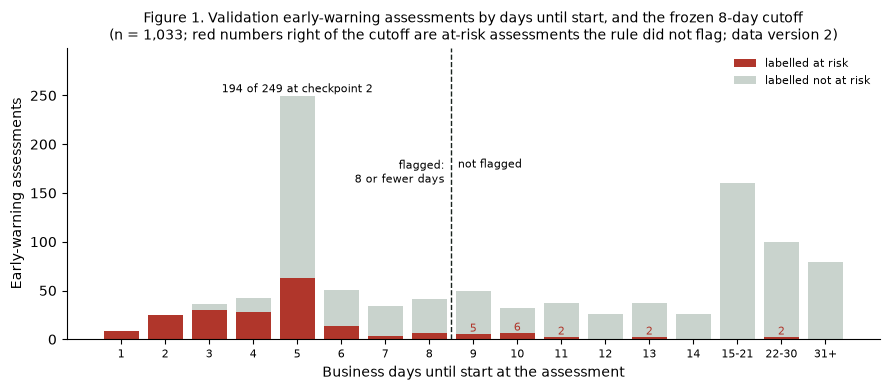

In [4]:
import matplotlib.pyplot as plt

flagged = v["days_rule"].astype(bool)
y = v["y"] == 1
BANDS = [(d, d, str(d)) for d in range(1, 15)] + [(15, 21, "15-21"), (22, 30, "22-30"), (31, 999, "31+")]
# The cutoff must fall between bands: no band may contain both 8 and 9 days
assert all(not (lo <= DAYS_THRESHOLD < hi) for lo, hi, _ in BANDS), "A band straddles the rule's cutoff"
band = pd.Series(pd.NA, index=v.index, dtype="string")
for lo, hi, label in BANDS:
    band[v["business_days_until_start"].between(lo, hi)] = label
assert band.notna().all(), "Every assessment needs a days band"

by_days = (v.assign(band=band, cp2=v["checkpoint"] == "checkpoint_2", at_risk=y, flagged=flagged)
           .groupby("band", sort=False)
           .agg(assessments=("assessment_id", "size"), checkpoint_2=("cp2", "sum"), at_risk=("at_risk", "sum"),
                rule_flags_seen=("flagged", "unique")))
by_days = by_days.reindex([label for _, _, label in BANDS])          # a band with no assessments gets zero counts
for c in ["assessments", "checkpoint_2", "at_risk"]:
    by_days[c] = by_days[c].fillna(0).astype(int)
by_days["not_at_risk"] = by_days["assessments"] - by_days["at_risk"]
by_days["at_risk_%"] = (100 * by_days["at_risk"] / by_days["assessments"]).where(by_days["assessments"] > 0)
by_days["flagged_by_rule"] = [hi <= DAYS_THRESHOLD for _, hi, _ in BANDS]      # from the band bounds
seen = by_days["rule_flags_seen"].dropna()
assert all(list(f) == [by_days.at[b, "flagged_by_rule"]] for b, f in seen.items()), \
    "The saved rule flags disagree with the band's position relative to the cutoff"
by_days = by_days[["assessments", "checkpoint_2", "at_risk", "not_at_risk", "at_risk_%", "flagged_by_rule"]]
by_days.index.name = "business_days_until_start"
by_days.insert(0, "data_version", DATA_VERSION)
by_days.to_csv(OUTPUT_DIR / "rule_by_days_validation.csv")

# Coordinator view, per 100 early-warning assessments (same denominators as notebook 04)
n = len(v)
tasks = v.assign(flag=flagged).groupby("request_id").agg(at_risk=("y", "max"), flagged=("flag", "any"))
coordinator = pd.Series({
    "flagged": 100 * flagged.sum() / n, "flagged and labelled at risk": 100 * (flagged & y).sum() / n,
    "flagged and labelled not at risk": 100 * (flagged & ~y).sum() / n,
    "at risk and not flagged (missed at that assessment)": 100 * (~flagged & y).sum() / n}, name="per 100 assessments")
print(f"Per 100 early-warning assessments, the rule flags {coordinator['flagged']:.0f}, including about "
      f"{coordinator['flagged and labelled at risk']:.0f} labelled at risk; about "
      f"{coordinator['at risk and not flagged (missed at that assessment)']:.1f} at-risk assessments per 100 are missed.")
print(f"Task level: {int((tasks['at_risk'].astype(bool) & tasks['flagged']).sum())} of {int(tasks['at_risk'].sum())} "
      f"at-risk validation tasks were flagged at least once.")
display(coordinator.round(1).to_frame())
display(by_days.drop(columns="data_version").round(1))

# Figure 1: counts by days until start, split by outcome, with the frozen cutoff
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(by_days))
ax.bar(x, by_days["at_risk"], color="#b0362b", label="labelled at risk")
ax.bar(x, by_days["not_at_risk"], bottom=by_days["at_risk"], color="#c9d3cd", label="labelled not at risk")
cut = by_days.index.get_loc(str(DAYS_THRESHOLD)) + 0.5
top = by_days["assessments"].max() * 1.2
ax.set_ylim(0, top)
ax.axvline(cut, color="#18221d", ls="--", lw=1)
ax.text(cut - 0.15, top * 0.62, f"flagged:\n{DAYS_THRESHOLD} or fewer days", ha="right", va="top", fontsize=8)
ax.text(cut + 0.15, top * 0.62, "not flagged", ha="left", va="top", fontsize=8)
five = by_days.index.get_loc("5")
ax.annotate(f"{by_days.loc['5', 'checkpoint_2']} of {by_days.loc['5', 'assessments']} at checkpoint 2",
            (five, by_days.loc["5", "assessments"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
missed = by_days.loc[~by_days["flagged_by_rule"], "at_risk"]
for label, k in missed[missed > 0].items():
    ax.annotate(str(k), (by_days.index.get_loc(label), k), xytext=(0, 2), textcoords="offset points",
                ha="center", fontsize=8, color="#b0362b")
ax.set_xticks(x, by_days.index, fontsize=8)
ax.set_xlabel("Business days until start at the assessment")
ax.set_ylabel("Early-warning assessments")
ax.set_title("Figure 1. Validation early-warning assessments by days until start, and the frozen 8-day cutoff\n"
             f"(n = {n:,}; red numbers right of the cutoff are at-risk assessments the rule did not flag; data version 2)",
             fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "rule_by_days_validation.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1 caption.** *What it shows:* the 1,033 validation early-warning assessments by business days until start, split into those labelled at risk and not at risk, with the frozen 8-day cutoff. Days 15 and above are grouped into wider bands: those bars show the total assessments across several days, not counts per day. Red numbers to the right of the cutoff are at-risk assessments the rule did not flag. *Why it matters:* most at-risk assessments sit close to the start date, which is why a days-until-start rule reaches most of them. Every assessment at 1–2 days was labelled at risk, as were 30 of 36 at 3 days and 28 of 42 at 4 days; the rule flags all assessments at those day counts. The 5-day bar shows a different pattern: 194 of its 249 assessments came from checkpoint 2, and 186 of the 249 were labelled not at risk. Checkpoint 2 accounts for 154 of the rule's 309 flags on not-at-risk assessments. To the right of the cutoff, 17 at-risk assessments were not flagged: 15 at 9–13 days and 2 at 22–30 days. Every one of their tasks was flagged later, at checkpoint 2 (notebook 04), so all 154 at-risk tasks received a flag in this validation sample; that does not show whether the later warning left enough time to act. *What it can't establish:* that 8 days is the best cutoff (it was chosen on training to reach 90% recall and is not re-tuned here), why a task ends up at risk, or how often this happens in real onboarding: the at-risk shares come from the generator's assumptions.

## C. What the comparison model relies on

The frozen policy does not use the logistic regression, but the model card has to explain why the simpler rule was preferred. Two views of the saved model are shown; nothing is refitted.

**Coefficients** (fitted on training data in notebook 02). The model adds up weighted inputs to get the log-odds of an at-risk outcome. The weights are read differently for the two kinds of input:

- **Numeric inputs** were standardised on training data, so each coefficient is the change in log-odds for a **one-training-standard-deviation** increase, with the other inputs held fixed. For days until start, the coefficient is also converted to **one business day**, which is easier to read.
- **Category inputs** are indicators compared with a **reference category** (the first category, dropped by the encoder). Each coefficient is the difference in log-odds from the reference, with the other inputs held fixed.

The odds multiplier (the exponential of the coefficient) is shown beside each one. Coefficients describe this model's weights; because inputs are related to each other (for example, checkpoint 2 assessments are both at 5 days and usually in progress), a weight is not the effect of that input on lateness.

**Permutation importance** on validation: one input at a time is shuffled across the validation assessments, the shuffled data is passed through the saved pipeline (so the shuffle happens before scaling and encoding), and the drop in **average precision** (how well at-risk assessments rise to the top of the ranking) and **ROC AUC** is recorded. Each input is shuffled 30 times with a fixed seed (2026), and the mean and standard deviation of the drop are reported. A larger drop means the model's ranking leans more on that input. Shuffling one input at a time breaks its links with the others too, so related inputs can share or mask each other's importance.

,input,level,compared_with,coefficient,odds_multiplier
0,business_days_until_start,+1 training SD,SD = 11.06,-4.544,0.011
1,business_days_until_start,+1 business day,one more day before the start,-0.411,0.663
2,business_days_in_current_status,+1 training SD,SD = 1.83,0.194,1.214
3,team_open_workload,+1 training SD,SD = 9.14,0.203,1.225
4,task_type,orientation_scheduling,reference: equipment_setup,-0.203,0.817
5,task_type,payroll_setup,reference: equipment_setup,0.037,1.038
6,task_type,system_access,reference: equipment_setup,-0.656,0.519
7,task_type,workplace_access,reference: equipment_setup,0.035,1.035
8,hiring_department,Finance,reference: Administration,0.438,1.550
9,hiring_department,Parks,reference: Administration,0.116,1.123


Unshuffled validation scores: average precision 0.707, ROC AUC 0.885 (30 shuffles per input, seed 2026)


,input,average_precision_drop_mean,average_precision_drop_sd,roc_auc_drop_mean,roc_auc_drop_sd
0,business_days_until_start,0.5019,0.0120,0.3718,0.0202
1,current_status,0.1417,0.0149,0.0353,0.0057
2,team_open_workload,0.0341,0.0066,0.0039,0.0023
3,task_type,0.0122,0.0086,0.0075,0.0029
4,business_days_in_current_status,0.0112,0.0098,0.0060,0.0014
5,hiring_department,0.0022,0.0035,0.0013,0.0011
6,intake_channel,-0.0015,0.0062,-0.0006,0.0012
7,info_issue_at_intake,-0.0028,0.0012,-0.0005,0.0004
8,employee_type,-0.0044,0.0040,0.0000,0.0013


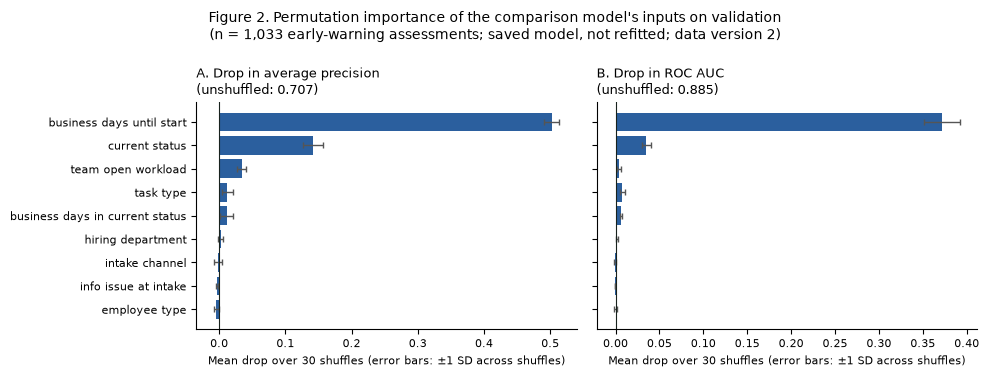

In [5]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score

prepare, logreg = model.named_steps["prepare"], model.named_steps["model"]
terms = pd.Series(logreg.coef_[0], index=prepare.get_feature_names_out())
saved_coef = pd.read_csv(OUTPUT_DIR / "coefficients.csv").set_index("term")["coefficient"]
assert np.allclose(terms.round(4), saved_coef.drop("intercept").loc[terms.index]), \
    "The model's coefficients differ from notebook 02's saved table"

scaling = pd.read_csv(OUTPUT_DIR / "numeric_scaling.csv").set_index("feature")
encoding = pd.read_csv(OUTPUT_DIR / "category_encoding.csv").set_index("feature")
rows = []
for term, coef in terms.items():
    kind, name = term.split("__", 1)
    if kind == "numeric":
        rows.append({"input": name, "level": "+1 training SD", "compared_with": f"SD = {scaling.at[name, 'training_sd']:.2f}",
                     "coefficient": coef, "odds_multiplier": np.exp(coef)})
        if name == "business_days_until_start":
            per_day = coef / scaling.at[name, "training_scale"]
            rows.append({"input": name, "level": "+1 business day", "compared_with": "one more day before the start",
                         "coefficient": per_day, "odds_multiplier": np.exp(per_day)})
    else:
        feature = next(f for f in encoding.index if name.startswith(f + "_"))
        rows.append({"input": feature, "level": name[len(feature) + 1:],
                     "compared_with": f"reference: {encoding.at[feature, 'reference_category']}",
                     "coefficient": coef, "odds_multiplier": np.exp(coef)})
coef_table = pd.DataFrame(rows)
coef_table.insert(0, "data_version", DATA_VERSION)
coef_table.to_csv(OUTPUT_DIR / "coefficients_explained.csv", index=False)
display(coef_table.drop(columns="data_version").round(3))

# Permutation importance on validation, through the saved pipeline (shuffling raw inputs before preprocessing)
X, y_true = v[FEATURES], v["y"]
base = {"average_precision": average_precision_score(y_true, model.predict_proba(X)[:, 1]),
        "roc_auc": roc_auc_score(y_true, model.predict_proba(X)[:, 1])}
ranking_02 = pd.read_csv(OUTPUT_DIR / "validation_ranking.csv", index_col=0)      # notebook 02 (rounded)
lr_02 = ranking_02.loc["Logistic regression (probability)"]
assert np.isclose(round(base["roc_auc"], 3), lr_02["ROC AUC"]) \
    and np.isclose(round(base["average_precision"], 4), lr_02["average precision"]), \
    "Unshuffled scores differ from notebook 02's saved ranking results"
N_REPEATS, PERM_SEED = 30, 2026
perm = permutation_importance(model, X, y_true, scoring=list(base), n_repeats=N_REPEATS, random_state=PERM_SEED)
importance = pd.DataFrame({
    "input": FEATURES,
    "average_precision_drop_mean": perm["average_precision"].importances_mean,
    "average_precision_drop_sd": perm["average_precision"].importances_std,
    "roc_auc_drop_mean": perm["roc_auc"].importances_mean,
    "roc_auc_drop_sd": perm["roc_auc"].importances_std,
}).sort_values("average_precision_drop_mean", ascending=False, ignore_index=True)
importance.insert(0, "data_version", DATA_VERSION)
importance["unshuffled_average_precision"] = base["average_precision"]
importance["unshuffled_roc_auc"] = base["roc_auc"]
importance["repeats"], importance["seed"] = N_REPEATS, PERM_SEED
importance.to_csv(OUTPUT_DIR / "permutation_importance_validation.csv", index=False)
print(f"Unshuffled validation scores: average precision {base['average_precision']:.3f}, "
      f"ROC AUC {base['roc_auc']:.3f} ({N_REPEATS} shuffles per input, seed {PERM_SEED})")
display(importance[["input", "average_precision_drop_mean", "average_precision_drop_sd",
                    "roc_auc_drop_mean", "roc_auc_drop_sd"]].round(4))

# Figure 2: drop in each score when one input is shuffled
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
order = importance.iloc[::-1]
labels = [f.replace("_", " ") for f in order["input"]]
for ax, score, title in [(axes[0], "average_precision", "A. Drop in average precision"),
                         (axes[1], "roc_auc", "B. Drop in ROC AUC")]:
    ax.barh(labels, order[f"{score}_drop_mean"], xerr=order[f"{score}_drop_sd"], color="#2b5f9e",
            error_kw={"ecolor": "#555555", "capsize": 2, "lw": 1})
    ax.axvline(0, color="#18221d", lw=0.8)
    ax.set_title(f"{title}\n(unshuffled: {base[score]:.3f})", fontsize=9, loc="left")
    ax.set_xlabel("Mean drop over 30 shuffles (error bars: ±1 SD across shuffles)", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Figure 2. Permutation importance of the comparison model's inputs on validation\n"
             f"(n = {len(v):,} early-warning assessments; saved model, not refitted; data version 2)", fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "permutation_importance_validation.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2 caption.** *What it shows:* for each of the comparison model's nine inputs, how much its validation ranking scores drop when that input alone is shuffled, averaged over 30 shuffles. The bars are the mean drops; the error bars show ±1 standard deviation across the shuffles, which describes how much the shuffles varied and is not a confidence interval. Panel A uses average precision (0.707 unshuffled) and panel B ROC AUC (0.885 unshuffled). *Why it matters:* the model leans overwhelmingly on **days until start**, the same input the rule uses. Shuffling it lowers average precision by 0.50 and ROC AUC by 0.37, to about 0.51, close to a ranking with no information. In the coefficients, each extra business day before the start multiplies the model's odds of an at-risk outcome by about 0.66, other inputs held fixed; this describes modelled odds, not a change in percentage points. Current status had the second-largest average-precision drop when shuffled (0.14). In this validation sample, status closely tracked checkpoint (all 839 checkpoint-1 assessments were open, and 186 of 194 checkpoint-2 assessments were in progress), so the analysis does not separate their roles. Shuffling team workload lowered average precision by about 0.03 on average; shuffling any other input changed it by about 0.01 or less, and some mean drops were slightly negative; that does not establish that removing those inputs would improve the model. Notebook 02 found that ranking by days until start alone reaches average precision 0.643 and ROC AUC 0.876, so the extra inputs add some ranking information, but at the frozen thresholds the model reached 1 more at-risk assessment while flagging 8 more (notebook 04). That is why the simpler rule was preferred. Employee type and hiring department, the two fields cleaning repaired, had small average effects on the validation ranking when shuffled; that does not show whether a repair changes a score or a flag for the 28 assessments with a filled value, which section E tests directly. *What it can't establish:* why tasks become at risk. Inputs are related (checkpoint 2 assessments are all at 5 days and mostly in progress), so shuffling one input also breaks its links with the others, and importance describes how this model uses its inputs on this validation sample, not their effect on lateness.

## D. When should the coordinator question the rule?

This section gathers validation evidence for the decision brief's guidance on when a person should question or override the rule. It is **descriptive**: it does not create or test a new rule, and the frozen policy does not change. Any rule built from these patterns would need new data to test it.

Two sides are described:

- **Misses:** the 17 at-risk assessments the rule did not flag, compared with a **pooled group** of not-at-risk assessments from the same checkpoint and day counts, so the comparison is not just "far from the start date versus close to it". The groups are not matched case by case, so they can have different proportions at each day count. Inputs are those available at the assessment, including the comparison model's score. With 17 misses, any difference is a description of this sample, not a reliable signal.
- **Flags on assessments that were not at risk:** where the rule's review volume goes, by checkpoint and by whether the task was already in progress with the team.

The section also checks what happened to each missed task afterwards: whether a later assessment (after the missed one, by timestamp) was flagged, and how much notice that gave. The follow-up is saved task by task.

In [6]:
missed = v[~flagged & y]
same_day = v[flagged.eq(False) & ~y & v.set_index(["checkpoint", "business_days_until_start"]).index
             .isin(missed.set_index(["checkpoint", "business_days_until_start"]).index)]
assert missed["checkpoint"].eq("checkpoint_1").all(), "Expected every missed assessment to be at checkpoint 1"
groups_d = {"missed at risk": missed, "same day count, not at risk": same_day}
print(f"Missed at-risk assessments: {len(missed)} (all at checkpoint 1, {missed['business_days_until_start'].min()}-"
      f"{missed['business_days_until_start'].max()} days before the start); comparison group: {len(same_day)} "
      "not-at-risk assessments at the same checkpoint and day counts")

# Numeric inputs and the comparison model's score: medians and quartiles
numeric_rows = []
for col in ["business_days_until_start", "team_open_workload", "business_days_in_current_status", "risk_probability"]:
    for g, rows_g in groups_d.items():
        q1, med, q3 = rows_g[col].quantile([0.25, 0.5, 0.75])
        numeric_rows.append({"input": col, "group": g, "assessments": len(rows_g), "median": med, "q1": q1, "q3": q3})
numeric_d = pd.DataFrame(numeric_rows)
numeric_d.insert(0, "data_version", DATA_VERSION)
numeric_d.to_csv(OUTPUT_DIR / "missed_vs_same_day_numeric_validation.csv", index=False)

# Category inputs: counts in each group (shares are shown for reading, but rest on small numbers)
cat_rows = []
for col in ["task_type", "employee_type", "hiring_department", "intake_channel", "info_issue_at_intake", "current_status"]:
    counts = pd.crosstab(pd.concat(groups_d.values())[col],
                         pd.concat({g: r[col] for g, r in groups_d.items()}).index.get_level_values(0))
    for level, row in counts.iterrows():
        cat_rows.append({"input": col, "level": level, **{g: int(row.get(g, 0)) for g in groups_d}})
category_d = pd.DataFrame(cat_rows)
for g, rows_g in groups_d.items():
    category_d[f"{g} %"] = 100 * category_d[g] / len(rows_g)
category_d.insert(0, "data_version", DATA_VERSION)
category_d.to_csv(OUTPUT_DIR / "missed_vs_same_day_categories_validation.csv", index=False)
display(numeric_d.drop(columns="data_version").round(3))
display(category_d.drop(columns="data_version").round(1))

# What happened to each missed task afterwards
later = v[v["request_id"].isin(missed["request_id"]) & (v["checkpoint"] == "checkpoint_2")]
follow_up = missed[["request_id", "assessment_id", "assessed_at", "business_days_until_start"]].merge(
    later[["request_id", "assessment_id", "assessed_at", "business_days_until_start", "days_rule"]], on="request_id",
    how="left", suffixes=("_missed", "_checkpoint_2"), validate="one_to_one")
follow_up = follow_up.rename(columns={"days_rule": "flagged_at_checkpoint_2"})
assert follow_up["flagged_at_checkpoint_2"].notna().all() and follow_up["flagged_at_checkpoint_2"].astype(bool).all(), \
    "Every missed task should have a flagged checkpoint-2 assessment in validation"
assert (follow_up["assessed_at_checkpoint_2"] > follow_up["assessed_at_missed"]).all(), \
    "Each checkpoint-2 flag must come after the missed assessment"
follow_up.insert(0, "data_version", DATA_VERSION)
follow_up.to_csv(OUTPUT_DIR / "missed_task_follow_up_validation.csv", index=False)
print(f"All {len(follow_up)} missed tasks were flagged at checkpoint 2, "
      f"{', '.join(str(int(d)) for d in sorted(follow_up['business_days_until_start_checkpoint_2'].unique()))} "
      "business days before the start.")

# Where flags on not-at-risk assessments go
not_at_risk_flags = (v[flagged & ~y].assign(in_progress=lambda x: x["current_status"] == "in_progress")
                     .groupby("checkpoint").agg(not_at_risk_flagged=("assessment_id", "size"),
                                                in_progress=("in_progress", "sum")))
not_at_risk_flags["in_progress"] = not_at_risk_flags["in_progress"].astype(int)
saved_04 = pd.read_csv(OUTPUT_DIR / "not_at_risk_flags_validation.csv")
saved_04 = saved_04[saved_04["method"] == "days rule"].set_index("checkpoint")
assert (not_at_risk_flags["not_at_risk_flagged"] == saved_04["not_at_risk_flagged"]).all() \
    and (not_at_risk_flags["in_progress"] == saved_04["in_progress"]).all(), "Differs from notebook 04's table"
display(not_at_risk_flags)

Missed at-risk assessments: 17 (all at checkpoint 1, 9-22 days before the start); comparison group: 151 not-at-risk assessments at the same checkpoint and day counts


,input,group,assessments,median,q1,q3
0,business_days_until_start,missed at risk,17,10.000,9.000,11.000
1,business_days_until_start,"same day count, not at risk",151,11.000,9.000,13.000
2,team_open_workload,missed at risk,17,14.000,9.000,19.000
3,team_open_workload,"same day count, not at risk",151,13.000,9.000,21.500
4,business_days_in_current_status,missed at risk,17,0.000,0.000,0.000
5,business_days_in_current_status,"same day count, not at risk",151,0.000,0.000,0.000
6,risk_probability,missed at risk,17,0.093,0.063,0.115
7,risk_probability,"same day count, not at risk",151,0.077,0.041,0.119


,input,level,missed at risk,"same day count, not at risk",missed at risk %,"same day count, not at risk %"
0,task_type,equipment_setup,2,20,11.8,13.2
1,task_type,orientation_scheduling,5,28,29.4,18.5
2,task_type,payroll_setup,5,41,29.4,27.2
3,task_type,system_access,4,35,23.5,23.2
4,task_type,workplace_access,1,27,5.9,17.9
5,employee_type,permanent,10,60,58.8,39.7
6,employee_type,seasonal,3,57,17.6,37.7
7,employee_type,temporary,4,34,23.5,22.5
8,hiring_department,Administration,1,13,5.9,8.6
9,hiring_department,Finance,3,8,17.6,5.3


All 17 missed tasks were flagged at checkpoint 2, 5 business days before the start.


,not_at_risk_flagged,in_progress
checkpoint,,
checkpoint_1,155,0
checkpoint_2,154,147


**What the comparison shows.** On the inputs available at the assessment, the 17 missed at-risk assessments look much like the pooled group of not-at-risk assessments from the same checkpoint and day counts: their team workload and time in the current status are similar, every one was still open, no task type stands out given only 17 assessments, and the comparison model gave them only slightly higher scores (median 0.093 against 0.077; 14 of the 17 stayed below its threshold). Permanent employees and requests with an information issue make up a larger share of the misses, but those are counts of a few assessments (10 of 17, and 3 of 17) and notebook 04 already noted permanent employees as the group closest to the review trigger. **This small descriptive comparison did not identify a clear early-warning signal in the recorded inputs.** A larger or more tightly matched analysis might find one.

All 17 tasks missed at checkpoint 1 were **flagged at checkpoint 2**, five business days before the start, and each of those flags came after the missed assessment. This gave the coordinator another opportunity to review them; the analysis does not show whether five days was enough to act, or that the later flag prevented a delay. On the other side, half of the rule's flags on not-at-risk assessments come from checkpoint 2 (154 of 309), and 147 of those 154 tasks were already in progress with the team.

**Guidance for the decision brief** (from this evidence; not a tested rule):

- **An unflagged early assessment is not an all-clear.** All 17 tasks missed at checkpoint 1 were flagged at checkpoint 2, five business days before the start. This gave the coordinator another opportunity to review them; the analysis does not show whether five days was enough to act. If that checkpoint is skipped or delayed, a manual check is a proposed safeguard.
- **A flag is a prompt to look, not a finding.** About 30 of every 100 assessments are flagged without being at risk. At checkpoint 2, 147 of the 154 flags on assessments later labelled not at risk were for tasks already in progress. Checking the task's status is a practical first step before deciding whether to follow up. These counts show review volume; they don't tell us how useful or time-consuming the checks would be.
- **Question the list when the inputs can't be trusted:** a missing or invalid days-until-start value goes to "needs manual check" under the frozen queue rules, and overdue tasks go to the separate urgent list.
- **Watch the permanent-employee group** in monitoring; notebook 04 noted it for review, and validation has too few misses to say more.